# LeetCode #378: Kth Smallest Element in a Sorted Matrix

https://leetcode.com/problems/kth-smallest-element-in-a-sorted-matrix/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Min-Heap (Merge K Sorted Lists)** | $O(k \log n)$ | $O(n)$ |
| **Optimal: Binary Search on Value ★** | $O(n \log(\text{max}-\text{min}))$ | $O(1)$ |

---

## Understanding the Methods

### Min-Heap (Merge K Sorted Lists)
Push the first element of each row into a min-heap. Pop the smallest element k times; after each pop, push the next element from the same row. The k-th popped element is the answer.

### Optimal: Binary Search on Value ★
Binary search on the answer value between `matrix[0][0]` and `matrix[n-1][n-1]`. For a candidate value `mid`, count how many elements are <= `mid` by starting from the bottom-left corner and walking up/right. If the count is >= k, search the left half; otherwise search the right half.

**Why this is better than Min-Heap:** The binary search approach runs in $O(n \log(\text{max}-\text{min}))$ time with $O(1)$ extra space, which is better when k is large. It exploits the row-and-column-sorted property to count elements efficiently.

**Constraints:**
* n == matrix.length == matrix[i].length
* 1 <= n <= 300
* -10^9 <= matrix[i][j] <= 10^9
* 1 <= k <= n^2

## Solutions

### C#

In [ ]:
public class Solution {
    public int KthSmallest(int[][] matrix, int k) {
        int n = matrix.Length;
        int lo = matrix[0][0], hi = matrix[n - 1][n - 1];
        while (lo < hi) {
            int mid = lo + (hi - lo) / 2;
            if (CountLessOrEqual(matrix, mid, n) >= k)
                hi = mid;
            else
                lo = mid + 1;
        }
        return lo;
    }

    private int CountLessOrEqual(int[][] matrix, int target, int n) {
        int count = 0, row = n - 1, col = 0;
        while (row >= 0 && col < n) {
            if (matrix[row][col] <= target) {
                count += row + 1;
                col++;
            } else {
                row--;
            }
        }
        return count;
    }
}

### Python

In [ ]:
class Solution:
    def kthSmallest(self, matrix: list[list[int]], k: int) -> int:
        n = len(matrix)
        lo, hi = matrix[0][0], matrix[n - 1][n - 1]
        while lo < hi:
            mid = (lo + hi) // 2
            count = 0
            row, col = n - 1, 0
            while row >= 0 and col < n:
                if matrix[row][col] <= mid:
                    count += row + 1
                    col += 1
                else:
                    row -= 1
            if count >= k:
                hi = mid
            else:
                lo = mid + 1
        return lo

### Go

In [ ]:
func kthSmallest(matrix [][]int, k int) int {
    n := len(matrix)
    lo, hi := matrix[0][0], matrix[n-1][n-1]
    for lo < hi {
        mid := lo + (hi-lo)/2
        count, row, col := 0, n-1, 0
        for row >= 0 && col < n {
            if matrix[row][col] <= mid {
                count += row + 1
                col++
            } else {
                row--
            }
        }
        if count >= k {
            hi = mid
        } else {
            lo = mid + 1
        }
    }
    return lo
}

### Rust

In [ ]:
impl Solution {
    pub fn kth_smallest(matrix: Vec<Vec<i32>>, k: i32) -> i32 {
        let n = matrix.len();
        let (mut lo, mut hi) = (matrix[0][0], matrix[n - 1][n - 1]);
        while lo < hi {
            let mid = lo + (hi - lo) / 2;
            let mut count = 0;
            let (mut row, mut col) = (n as i32 - 1, 0usize);
            while row >= 0 && col < n {
                if matrix[row as usize][col] <= mid {
                    count += row + 1;
                    col += 1;
                } else {
                    row -= 1;
                }
            }
            if count >= k {
                hi = mid;
            } else {
                lo = mid + 1;
            }
        }
        lo
    }
}

## Example Scenarios

### 1. Common Case — Binary Search on Value
**Input:** `matrix = [[1,5,9],[10,11,13],[12,13,15]], k = 8`
Guess a value `mid` in the range `[1, 15]`. For each guess, count how many elements are $\le mid$ using a staircase walk that starts at the bottom-left corner. Shrink the range: if `count >= k` move `hi` down, else move `lo` up. The loop converges to the smallest value whose count reaches `k`.
Sorted order is `1,5,9,10,11,12,13,13,15`; the 8th smallest is **13**. **Output:** `13`

### 2. Slightly Complex — Duplicate Values
**Input:** `matrix = [[1,2],[1,3]], k = 2`
Counting elements $\le mid$ handles duplicates automatically — the answer may repeat a value. Sorted order `1,1,2,3`, so the 2nd smallest is the second `1`. **Output:** `1`

### 3. Edge Case: Time Factor — Range Drives the Steps
**Input:** `matrix = [[1,2],[3,4]], k = 4`
Time is $O(n \log(\text{max}-\text{min}))$: about $\log(\text{max}-\text{min})$ guesses, each an $O(n)$ staircase count. The largest `k = n*n` always resolves to `matrix[n-1][n-1]`. **Output:** `4`

### 4. Edge Case: Space Factor — Single Cell, O(1) Extra
**Input:** `matrix = [[-5]], k = 1`
Only `lo`, `hi`, `mid` are stored — no heap — so extra space is $O(1)$ no matter how large the matrix. Here `lo == hi` immediately. **Output:** `-5`

### 5. Almost-Impossible but Plausible — k = 1
**Input:** `matrix = [[1,3,5],[6,7,12],[11,14,20]], k = 1`
`k = 1` must return the global minimum, which in a row- and column-sorted matrix is always the top-left corner `matrix[0][0]`. **Output:** `1`


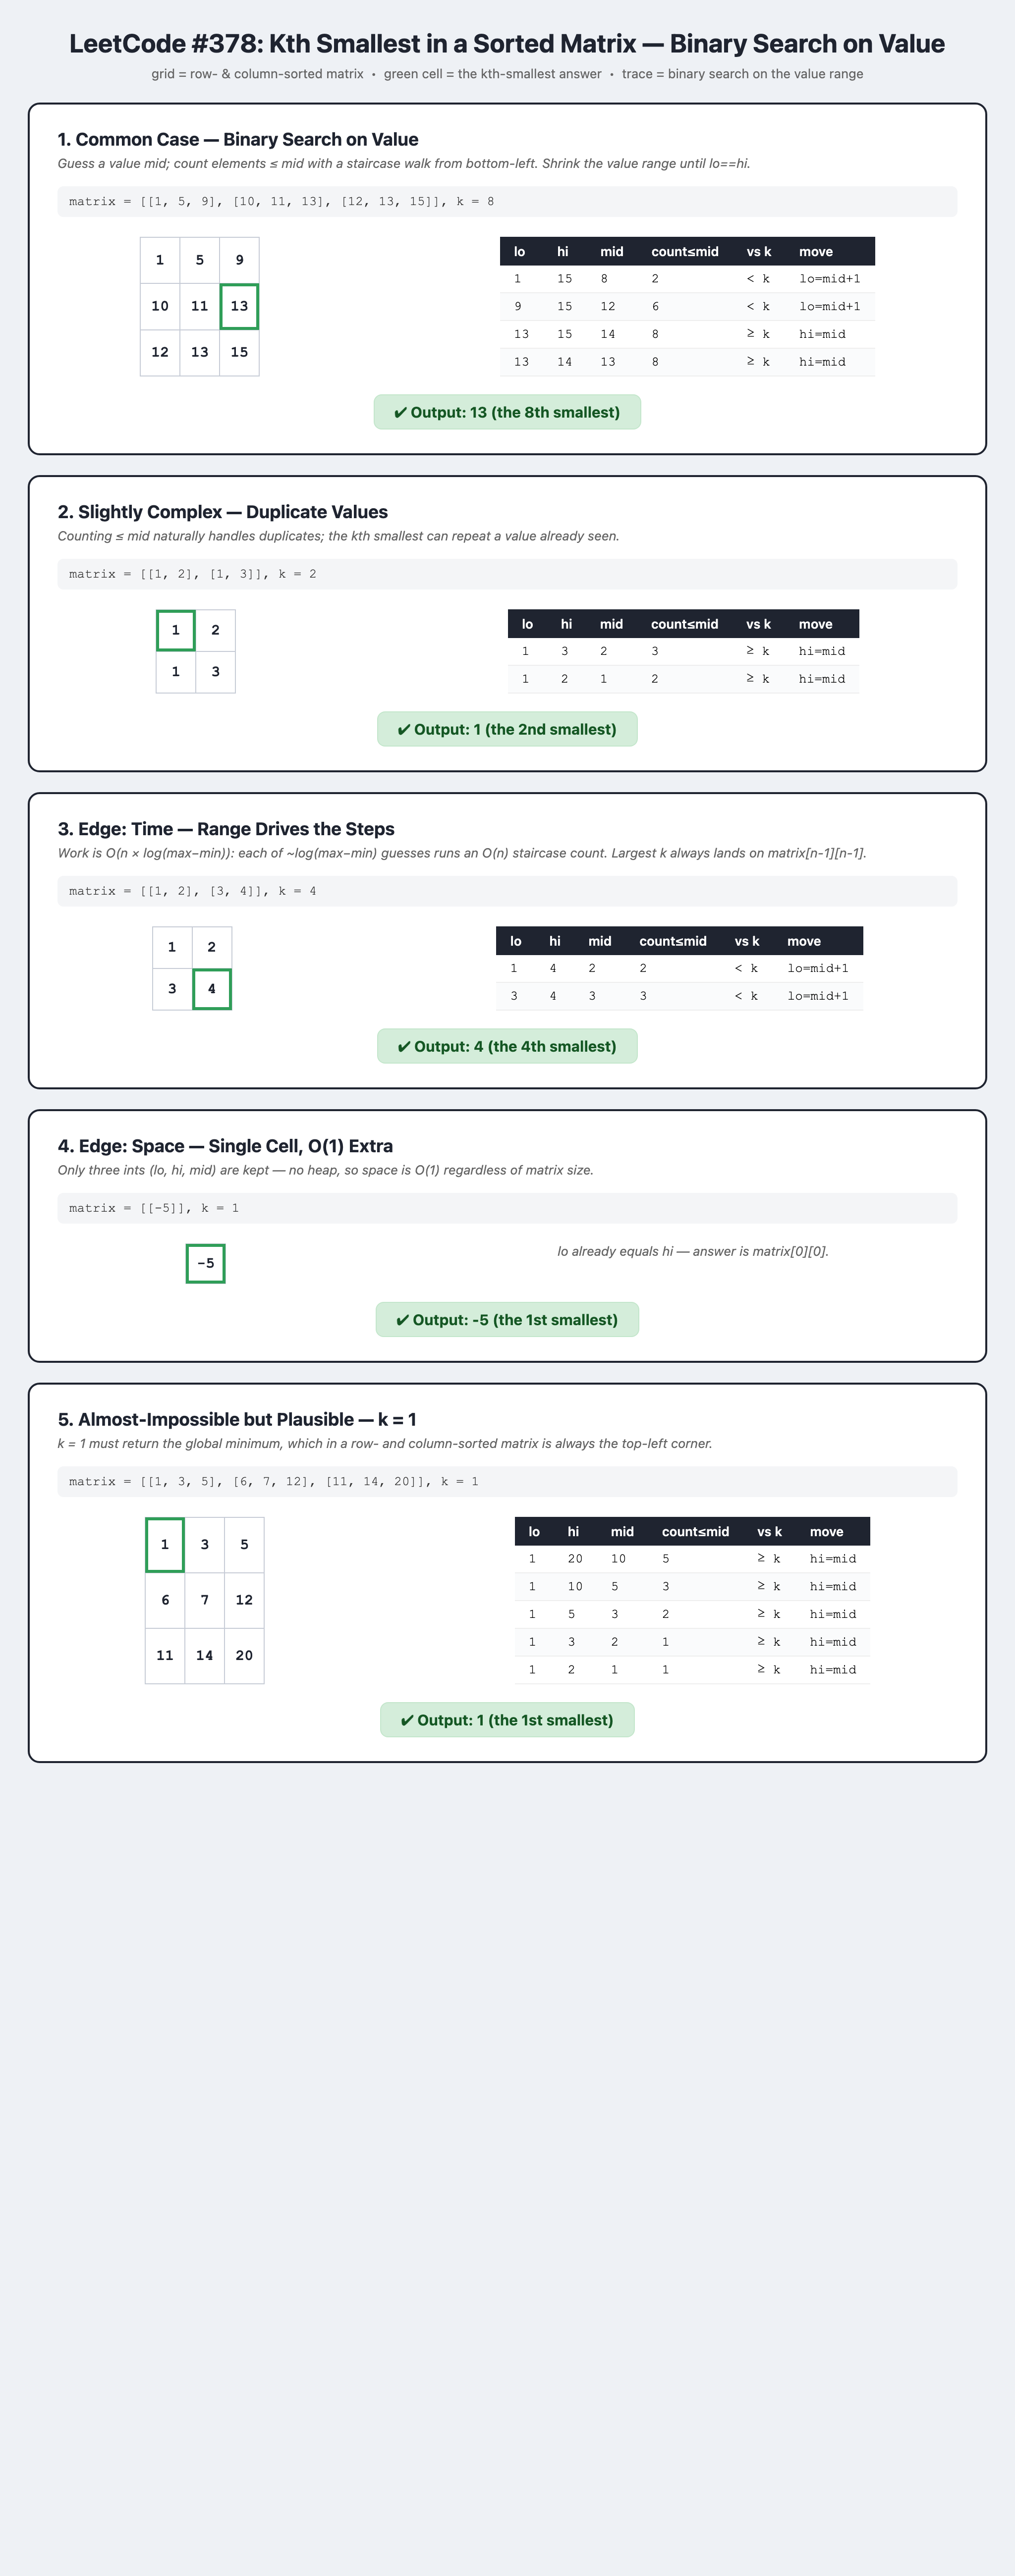